In [1]:
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from scipy.spatial.distance import pdist
from scipy.stats import chi2
from sklearn.preprocessing import quantile_transform
from scipy.spatial.distance import mahalanobis
from numpy.linalg import inv
from tqdm import tqdm
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
save_dir = "/home/s4634945/soft_links/Q5058/IOC/Benchmark_results/"

#### Load data

In [2]:
import pickle

# --- Load gene expression matrices ---
with open("ModWGCNA_gene_expression_matrices.pkl", "rb") as f:
    expr_dict = pickle.load(f)
young_liver_expr = expr_dict["young_liver"]
young_brain_expr = expr_dict["young_brain_hypothalamus"]
aged_liver_expr = expr_dict["aged_liver"]
aged_brain_expr = expr_dict["aged_brain_hypothalamus"]

# --- Load phenotype tables ---
with open("ModWGCNA_phenotype_tables.pkl", "rb") as f:
    pheno_dict = pickle.load(f)
young_liver_pheno = pheno_dict["young_liver"]
young_brain_pheno = pheno_dict["young_brain_hypothalamus"]
aged_liver_pheno = pheno_dict["aged_liver"]
aged_brain_pheno = pheno_dict["aged_brain_hypothalamus"]

#### Functions for data processing

In [3]:
def reduce_features_svd(expression: pd.DataFrame, n_components: int = 20) -> pd.DataFrame:
    """
    Perform SVD-based dimensionality reduction on gene expression data.

    Parameters:
    expression: DataFrame of shape (samples, genes)
    n_components: number of components to keep

    Returns:
    reduced_data: DataFrame of shape (samples, n_components)
    """
    svd = TruncatedSVD(n_components=n_components)
    reduced = svd.fit_transform(expression)
    cols = [f"PC{i+1}" for i in range(n_components)]
    return pd.DataFrame(reduced, index=expression.index, columns=cols)


def detect_outliers_mahalanobis(data: pd.DataFrame, cutoff_percent: float = 0.02) -> pd.Index:
    """
    Detect sample outliers using Mahalanobis distance.

    Parameters:
    data: DataFrame of shape (samples, features)
    cutoff_percent: fraction of samples to label as outliers

    Returns:
    outlier_indices: Index of samples flagged as outliers
    """
    cov = np.cov(data.values, rowvar=False)
    inv_cov = inv(cov)
    mean = data.mean(axis=0).values
    dists = data.apply(lambda row: mahalanobis(row.values, mean, inv_cov), axis=1)
    threshold = np.percentile(dists, 100 * (1 - cutoff_percent))
    return data.index[dists > threshold]


def quantile_normalize(df: pd.DataFrame) -> pd.DataFrame:
    """
    Apply quantile normalization across samples.

    Parameters:
    df: DataFrame of shape (samples, genes)

    Returns:
    normalized_df: DataFrame same shape as input
    """
    arr = quantile_transform(df.values, axis=0, copy=True)
    return pd.DataFrame(arr, index=df.index, columns=df.columns)


def regress_out_confounds_df(expr_df: pd.DataFrame,
                             confounds: pd.DataFrame) -> pd.DataFrame:
    """
    Regress out confounding factors from every gene in an expression DataFrame.

    Parameters:
    -----------
    expr_df : pd.DataFrame
        Gene‐expression matrix, shape (n_samples, n_genes).
    confounds : pd.DataFrame
        Confounder matrix, shape (n_samples, n_covariates).
        Rows must align with expr_df.

    Returns:
    --------
    pd.DataFrame
        Residualized expression matrix, same shape and index/columns as expr_df.
    """
    # Build design matrix X (n_samples × (n_covariates + 1))
    X = confounds.copy()
    X['intercept'] = 1
    X_mat = X.values                          # shape (n_samples, p)
    
    # Response matrix Y (n_samples × n_genes)
    Y_mat = expr_df.values                    # shape (n_samples, g)

    # Solve for B in least squares: X B = Y  →  B = (X'X)^{-1} X' Y
    #   B will have shape (p, g)
    XtX_inv = np.linalg.inv(X_mat.T.dot(X_mat))
    B = XtX_inv.dot(X_mat.T).dot(Y_mat)

    # Predicted values: Y_hat = X B  (n_samples × g)
    Y_hat = X_mat.dot(B)

    # Residuals: Y_resid = Y − Y_hat
    resid = Y_mat - Y_hat

    # Wrap back into DataFrame
    resid_df = pd.DataFrame(resid,
                            index=expr_df.index,
                            columns=expr_df.columns)
    return resid_df



def select_top_variant_genes(expression: pd.DataFrame, max_genes: int) -> pd.Index:
    """
    Select most variant genes based on standard deviation.

    Parameters:
    expression: DataFrame of shape (samples, genes)
    max_genes: maximum number of genes to select

    Returns:
    top_genes: Index of selected genes
    """
    stds = expression.std(axis=0)
    top = stds.nlargest(max_genes).index
    return top

#### Mod.WGCNA functions

In [4]:
from scipy.cluster.hierarchy import dendrogram
def plot_dendrogram_and_cut(Z, cut_height=0.95):
    plt.figure(figsize=(15, 6))
    
    # Plot dendrogram
    dendro = dendrogram(Z, no_plot=False, no_labels=True)
    
    # Draw your proposed cut line
    plt.axhline(y=cut_height, c='r', linestyle='--', label=f'Cut Height {cut_height}')
    plt.title("Gene Co-expression Dendrogram")
    plt.ylabel("Dissimilarity (1 - TOM)")
    plt.legend()
    plt.show()
    
    # Apply the cut based on distance (height)
    # This mimics the "95% threshold" mentioned in your text
    labels = fcluster(Z, t=cut_height, criterion='distance')
    
    n_clusters = len(np.unique(labels))
    print(f"Cutting at height {cut_height} resulted in {n_clusters} clusters.")
    return labels

In [5]:
def calculate_adjacency(expression: pd.DataFrame, beta: float) -> pd.DataFrame:
    """
    Compute adjacency matrix from expression via soft-thresholded Pearson correlation.

    Parameters:
    expression: DataFrame (samples, traits)
    beta: soft thresholding power

    Returns:
    adjacency: DataFrame (traits, traits)
    """
    corr = expression.corr().abs()
    adj = corr.pow(beta)
    return adj


def align_samples_by_donor(data_dict):
    """
    Standardizes indices to 'GTEX-XXXX' format and finds the common intersection.
    """
    aligned_dict = {}
    donor_indices = []
    
    # 1. Truncate IDs to 'GTEX-XXXX'
    for tissue, df in data_dict.items():
        # GTEx IDs are hyphen-separated. First two parts = Donor ID.
        # e.g., 'GTEX-131XH-0626...' -> 'GTEX-131XH'
        
        # Create a copy to avoid SettingWithCopy warnings
        df = df.copy()
        
        # Apply lambda to index
        df.index = df.index.map(lambda x: '-'.join(x.split('-')[:2]))
        
        # Handle duplicates if a donor has multiple samples for one tissue (rare but possible)
        # Taking mean is a safe bet, or 'first'
        if df.index.duplicated().any():
            print(f"Warning: Duplicate donors found in {tissue}, taking mean expression.")
            df = df.groupby(level=0).mean()
            
        aligned_dict[tissue] = df
        donor_indices.append(set(df.index))
    
    # 2. Find intersection of donors across ALL tissues
    common_donors = set.intersection(*donor_indices)
    common_donors = sorted(list(common_donors))
    print(f"Found {len(common_donors)} common donors across tissues.")
    
    # 3. Filter all dataframes to this common list
    final_dict = {}
    for tissue, df in aligned_dict.items():
        final_dict[tissue] = df.loc[common_donors]
        
    return final_dict


import numpy as np
import pandas as pd
from tqdm import tqdm

def build_multitissue_adjacency(data_dict: dict, beta_intra: float = 6, beta_inter: float = 3, max_genes: int = 5000) -> pd.DataFrame:
    """
    Build a multi-tissue adjacency matrix with different powers for intra- and inter-tissue correlations.

    Parameters:
    data_dict: dict mapping tissue names to expression DataFrames (samples x genes)
    beta_intra: soft threshold for within-tissue correlations
    beta_inter: soft threshold for between-tissue correlations
    max_genes: maximum number of genes per tissue

    Returns:
    adjacency: DataFrame indexed by (tissue, gene) pairs containing the adjusted correlation values
    """
    # Select top genes per tissue with progress bar
    selected = {}
    for tissue, expr in data_dict.items():
        top = select_top_variant_genes(expr, max_genes)
        selected[tissue] = expr[top]

    # (Optional) Iterate over selected tissues and genes to create a traits list
    traits = []
    for tissue, df in tqdm(selected.items(), desc="Processing selected tissues", total=len(selected)):
        for gene in tqdm(df.columns, desc=f"Processing genes for {tissue}", leave=False, total=len(df.columns)):
            traits.append((tissue, gene))

    # Build combined DataFrame by concatenating each gene series with its tissue label
    dfs = {}
    for tissue in tqdm(selected, desc="Concatenating data from tissues", total=len(selected)):
        for gene in tqdm(selected[tissue].columns, desc=f"Concatenating genes for {tissue}", leave=False, total=len(selected[tissue].columns)):
            dfs[(tissue, gene)] = selected[tissue][gene]
    combined = pd.concat(dfs, axis=1)
    combined.columns = pd.MultiIndex.from_tuples([col[:2] for col in combined.columns])

    # Compute correlation matrix from the combined data
    corr = combined.corr().abs()
    vals = combined.values  # shape: (num_samples, num_features)

    # --- Vectorized computation of the adjacency matrix ---
    # 1. Extract tissue labels from the index (which is a MultiIndex (tissue, gene))
    tissues_idx = np.array([t for t, _ in corr.index])
    tissues_col = np.array([t for t, _ in corr.columns])

    # 2. Create a boolean mask where tissues match (True for intra-tissue pairs)
    intra_mask = (tissues_idx[:, None] == tissues_col[None, :])  # shape (N, N)

    # 3. Create an exponent matrix, using beta_intra where tissues match and beta_inter otherwise
    exponent = np.where(intra_mask, beta_intra, beta_inter)

    # 4. Compute the adjacency matrix in a fully vectorized manner
    adj_values = np.power(corr.values, exponent)
    adj = pd.DataFrame(adj_values, index=corr.index, columns=corr.columns)

    return adj

def compute_tom(adj):
    
    # Convert input to numpy array if it is a DataFrame
    if hasattr(adj, "values"):
        A = adj.values.copy()
        node_labels = adj.index.tolist()
    else:
        A = np.array(adj)
#         node_labels = list(range(A.shape[0]))
    
    # --- FIX: Enforce bounds [0, 1] ---
    A = np.clip(A, 0, 1)
    # Ensure diagonal is pure 1.0 (sometimes self-correlation misses slightly)
    np.fill_diagonal(A, 1.0)

    n = A.shape[0]
    
    # Check adjacency matrix
    if not np.allclose(A, A.T):
        print("Warning: Adjacency matrix is not symmetric")
    if np.any(A < 0) or np.any(A > 1):
        print("Warning: Adjacency matrix contains values outside [0,1]")
    if np.any(np.isnan(A)):
        print("Warning: Adjacency matrix contains NaNs")
    
    # Compute connectivity
    k = A.sum(axis=1)
    
    # Compute shared neighborhood matrix
    L = np.dot(A, A)
    
    # Minimum connectivity between pairs
    deg_min = np.minimum.outer(k, k)
    
    # Compute TOM
    TOM = (L + A) / (deg_min + 1 - A)
    np.fill_diagonal(TOM, 1)
    
    # Debugging: Check TOM values
    print("TOM min:", TOM.min(), "max:", TOM.max(), "mean:", TOM.mean())
    
    # Compute dissimilarity
    dissimilarity = 1 - TOM
    print("Dissimilarity min:", dissimilarity.min(), "max:", dissimilarity.max(), "mean:", dissimilarity.mean())
    dissimilarity = np.clip(dissimilarity, 0, 1)        # 1. Remove negatives and >1
    np.fill_diagonal(dissimilarity, 0)                  # 2. Ensure self-distance is 0

#     # Step 1: Compute pairwise distance
#     distance_matrix = pdist(dissimilarity, metric='euclidean')
    
#     # Step 2: Perform hierarchical clustering (you can choose method: 'ward', 'single', 'complete', etc.)
#     Z = linkage(distance_matrix, method='ward')

    condensed_dist = squareform(dissimilarity, checks=False)
    
    # 2. Perform hierarchical clustering
    # Standard WGCNA uses 'average', but 'ward' is fine if that's your specific intent.
    Z = linkage(condensed_dist, method='ward')
    
    return dissimilarity, Z

In [6]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def find_optimal_clusters(Z, dissimilarity, max_k=20):
    scores = []
    k_values = range(2, max_k + 1)
    
    # We need the condensed distance matrix for linkage, 
    # but the full square matrix for silhouette_score.
    # Assuming 'dissimilarity' is your N x N matrix from previous step.
    
    print("Calculating Silhouette Scores for k clusters...")
    for k in k_values:
        # Cut the tree to get exactly k clusters
        labels = fcluster(Z, k, criterion='maxclust')
        
        # Calculate score (higher is better, range -1 to 1)
        score = silhouette_score(dissimilarity, labels, metric='precomputed')
        scores.append(score)
        print(f"k={k}, Score={score:.4f}")
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(k_values, scores, marker='o')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.title('Silhouette Analysis for Optimal k')
    plt.grid(True)
    plt.show()
    
    # Return best k
    best_k = k_values[np.argmax(scores)]
    return best_k

#### Pre-processing

In [7]:
liver_expr = pd.concat([young_liver_expr,aged_liver_expr])
liver_expr = liver_expr.loc[:, ~liver_expr.columns.duplicated()]
liver_expr = np.log2(liver_expr + 1)
brain_expr = pd.concat([young_brain_expr,aged_brain_expr])
brain_expr = brain_expr.loc[:, ~brain_expr.columns.duplicated()]
brain_expr = np.log2(brain_expr + 1)

liver_pheno = pd.concat([young_liver_pheno,aged_liver_pheno])
brain_pheno = pd.concat([young_brain_pheno,aged_brain_pheno])

In [8]:
liver_svd = reduce_features_svd(liver_expr)
brain_svd = reduce_features_svd(brain_expr)

liver_outliers = detect_outliers_mahalanobis(liver_svd)
brain_outliers = detect_outliers_mahalanobis(brain_svd)

liver_expr = liver_expr[~liver_expr.index.isin(list(liver_outliers))]
brain_expr = brain_expr[~brain_expr.index.isin(list(brain_outliers))]

common_samples = set(brain_expr.index.str.split("-").str[:2].str.join("-")).intersection(set(liver_expr.index.str.split("-").str[:2].str.join("-")))

brain_expr = brain_expr[brain_expr.index.str.split("-").str[:2].str.join("-").isin(common_samples)]
liver_expr = liver_expr[liver_expr.index.str.split("-").str[:2].str.join("-").isin(common_samples)]

liver_pheno = liver_pheno[liver_pheno['SAMPID_2'].isin(common_samples)]
liver_pheno.drop(columns=['AGE','SAMPID_2'],inplace=True)
brain_pheno = brain_pheno[brain_pheno['SAMPID_2'].isin(common_samples)]
brain_pheno.drop(columns=['AGE','SAMPID_2'],inplace=True)

In [9]:
# Quantile Normalisation
liver_quant_norm = quantile_normalize(liver_expr)
brain_quant_norm = quantile_normalize(brain_expr)

# Regress out covariate effects
liver_quant_norm_corrected = regress_out_confounds_df(liver_quant_norm,liver_pheno)
brain_quant_norm_corrected = regress_out_confounds_df(brain_quant_norm,brain_pheno)

common_samples_liver_aged = liver_quant_norm_corrected[liver_quant_norm_corrected.index.isin(aged_liver_expr.index)]
common_samples_brain_aged = brain_quant_norm_corrected[brain_quant_norm_corrected.index.isin(aged_brain_expr.index)]

/home/s4634945/conda_env/.conda/envs/MachineLearning/lib/python3.8/site-packages/sklearn/preprocessing/_data.py:2667: UserWarning: n_quantiles (1000) is greater than the total number of samples (43). n_quantiles is set to n_samples.
  warnings.warn(
/home/s4634945/conda_env/.conda/envs/MachineLearning/lib/python3.8/site-packages/sklearn/preprocessing/_data.py:2667: UserWarning: n_quantiles (1000) is greater than the total number of samples (43). n_quantiles is set to n_samples.
  warnings.warn(


In [10]:
common_samples_liver_young = liver_quant_norm_corrected[~liver_quant_norm_corrected.index.isin(aged_liver_expr.index)]
common_samples_brain_young = brain_quant_norm_corrected[~brain_quant_norm_corrected.index.isin(aged_brain_expr.index)]

##### Young

Found 24 common donors across tissues.


Processing genes for Liver_young:   0%|          | 0/5000 [00:00<?, ?it/s]
                                                                          
Concatenating data from tissues: 100%|██████████| 2/2 [00:00<00:00,  8.01it/s]             


TOM min: 0.0007190519761234032 max: 1.0 mean: 0.010935755911344807
Dissimilarity min: 0.0 max: 0.9992809480238766 mean: 0.9890642440886551


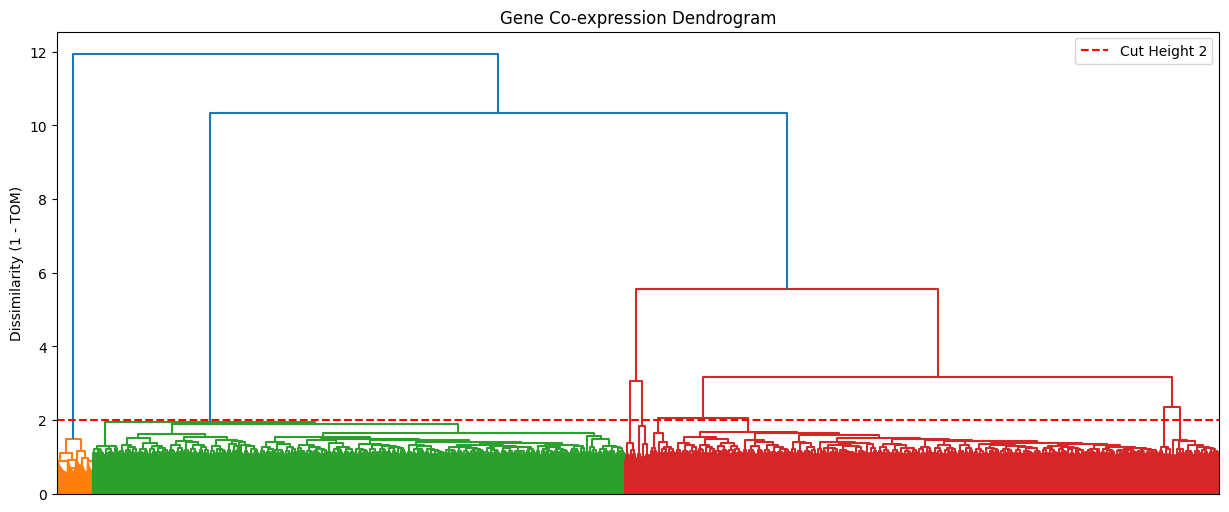

Cutting at height 2 resulted in 8 clusters.


In [11]:
young_data_dict = {
    "Liver_young": common_samples_liver_young,
    "Brain_young": common_samples_brain_young}
young_aligned_data_dict = align_samples_by_donor(young_data_dict)
young_brain_liver_multi_tissue = build_multitissue_adjacency(young_aligned_data_dict)
young_brain_liver_multi_tissue = young_brain_liver_multi_tissue.fillna(0)
young_dissimilarity, young_Z = compute_tom(young_brain_liver_multi_tissue)
young_labels = plot_dendrogram_and_cut(young_Z, cut_height=2) # Adjust 0.7 visually

# best_k = find_optimal_clusters(young_Z, young_dissimilarity, max_k=100)

In [12]:
young_clusters_by_k = fcluster(young_Z, t=8, criterion='maxclust')
young_df = pd.DataFrame(young_clusters_by_k,index=young_brain_liver_multi_tissue.index.map("_".join),columns=["cluster"])

young_df['gene'] = young_df.index.str.split('_', n=2).str[2]
young_df['organ'] = young_df.index.str.split('_', n=2).str[0]
clusters_with_both = young_df.groupby('cluster')['organ'].nunique()
clusters_to_keep = clusters_with_both[clusters_with_both == 2].index
young_result = young_df[young_df['cluster'].isin(clusters_to_keep)]

##### Aged

Found 19 common donors across tissues.


Processing genes for Liver_aged:   0%|          | 0/5000 [00:00<?, ?it/s]
                                                                         
Concatenating data from tissues: 100%|██████████| 2/2 [00:00<00:00,  8.21it/s]            


TOM min: 0.001252285541486275 max: 1.0 mean: 0.012830084094063306
Dissimilarity min: 0.0 max: 0.9987477144585137 mean: 0.987169915905933


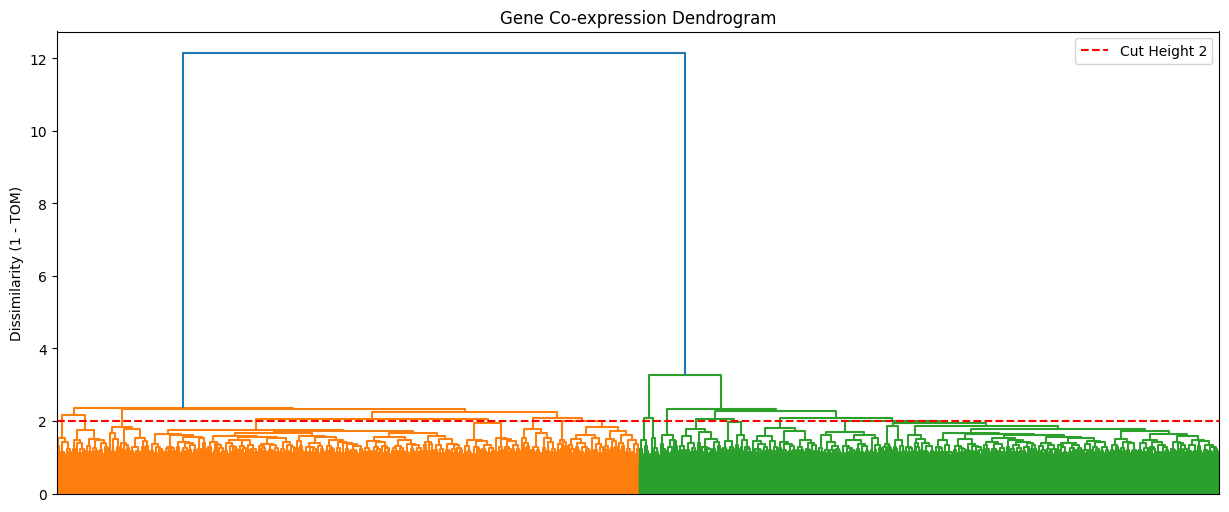

Cutting at height 2 resulted in 15 clusters.


In [13]:
aged_data_dict = {
    "Liver_aged": common_samples_liver_aged,
    "Brain_aged": common_samples_brain_aged}
aged_aligned_data_dict = align_samples_by_donor(aged_data_dict)
aged_brain_liver_multi_tissue = build_multitissue_adjacency(aged_aligned_data_dict)
aged_brain_liver_multi_tissue = aged_brain_liver_multi_tissue.fillna(0)
aged_dissimilarity, aged_Z = compute_tom(aged_brain_liver_multi_tissue)
# best_k = find_optimal_clusters(aged_Z, aged_dissimilarity, max_k=100)
aged_labels = plot_dendrogram_and_cut(aged_Z, cut_height=2) # Adjust 0.7 visually

In [14]:
aged_clusters_by_k = fcluster(aged_Z, t=15, criterion='maxclust')
aged_df = pd.DataFrame(aged_clusters_by_k,index=aged_brain_liver_multi_tissue.index.map("_".join),columns=["cluster"])

aged_df['gene'] = aged_df.index.str.split('_', n=2).str[2]
aged_df['organ'] = aged_df.index.str.split('_', n=2).str[0]
clusters_with_both = aged_df.groupby('cluster')['organ'].nunique()
clusters_to_keep = clusters_with_both[clusters_with_both == 2].index
aged_result = aged_df[aged_df['cluster'].isin(clusters_to_keep)]

#### MDC

In [15]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

def calculate_mdc(adj_young, adj_old, module_labels, n_permutations=1000, seed=42):
    """
    Calculates Module Differential Connectivity (MDC) and significance.
    
    Args:
        adj_young: pd.DataFrame (Genes x Genes) - Adjacency matrix for Young
        adj_old: pd.DataFrame (Genes x Genes) - Adjacency matrix for Old (must be aligned with young)
        module_labels: pd.Series or dict - Mapping of Gene -> Module Label (based on Young clustering)
        n_permutations: int - Number of random gene sets to sample for significance
        
    Returns:
        results_df: DataFrame containing MDC, p-values, and stats for each module.
    """
    np.random.seed(seed)
    
    # 1. Align Data
    common_genes = sorted(list(set(adj_young.index) & set(adj_old.index) & set(module_labels.keys())))
    print(f"Aligning matrices. {len(common_genes)} common genes found.")
    
    adj_Y = adj_young.loc[common_genes, common_genes].values
    adj_O = adj_old.loc[common_genes, common_genes].values
    
    # Map genes to integer indices for speed
    gene_to_idx = {g: i for i, g in enumerate(common_genes)}
    modules = pd.Series(module_labels).loc[common_genes]
    unique_modules = modules.unique()
    
    # Helper to calculate connectivity (Average Adjacency)
    # Using average instead of sum normalized against size^2 to handle different module sizes in permutation
    def get_connectivity(adj_matrix, indices):
        if len(indices) <= 1: return 0.0
        # Extract submatrix
        sub = adj_matrix[np.ix_(indices, indices)]
        # Sum of weights (upper triangle to avoid double counting + diagonal)
        # Using full mean is equivalent since matrices are symmetric and diagonal is processed consistently
        return np.mean(sub) 

    results = []

    # 2. Iterate Modules
    print(f"Calculating MDC for {len(unique_modules)} modules...")
    
    for mod in tqdm(unique_modules):
        if mod == -1: continue # Skip noise/unclustered if labeled -1
            
        genes_in_mod = modules[modules == mod].index
        idxs = [gene_to_idx[g] for g in genes_in_mod]
        n_genes = len(idxs)
        
        # A. Observed Connectivity
        conn_Y = get_connectivity(adj_Y, idxs)
        conn_O = get_connectivity(adj_O, idxs)
        
        # Avoid division by zero
        if conn_O == 0: mdc = np.nan
        else:           mdc = conn_Y / conn_O
            
        # B. Permutation Test
        # Sample random genes of size N from the background and calculate their MDC
        perm_mdcs = []
        all_indices = np.arange(len(common_genes))
        
        for _ in range(n_permutations):
            rand_idxs = np.random.choice(all_indices, size=n_genes, replace=False)
            
            r_conn_Y = get_connectivity(adj_Y, rand_idxs)
            r_conn_O = get_connectivity(adj_O, rand_idxs)
            
            if r_conn_O == 0: r_mdc = 0 # Handle edge case
            else:             r_mdc = r_conn_Y / r_conn_O
            
            perm_mdcs.append(r_mdc)
            
        perm_mdcs = np.array(perm_mdcs)
        
        # C. P-value
        # Two-sided test? Or check for Gain (MDC>1) or Loss (MDC<1)
        # The paper highlights GOC (Gain) and LOC (Loss).
        # P-value = fraction of random MDCs more extreme than observed
        
        if mdc > 1: # Testing for Gain of Connectivity
            p_val = np.sum(perm_mdcs >= mdc) / n_permutations
        else:       # Testing for Loss of Connectivity
            p_val = np.sum(perm_mdcs <= mdc) / n_permutations
            
        # Sanity cap for p-value
        if p_val == 0: p_val = 1 / n_permutations
            
        results.append({
            'Module': mod,
            'Size': n_genes,
            'Conn_Young': conn_Y,
            'Conn_Old': conn_O,
            'MDC': mdc,
            'P_Value': p_val,
            'Type': 'GOC' if mdc > 1 else 'LOC'
        })
        
    results_df = pd.DataFrame(results)
    
    # 3. FDR Correction
    if not results_df.empty:
        _, pvals_corrected, _, _ = multipletests(results_df['P_Value'], alpha=0.05, method='fdr_bh')
        results_df['FDR'] = pvals_corrected
        
    return results_df#.sort_values('MDC', ascending=False)

# genes_index = young_brain_liver_multi_tissue.index.get_level_values(1) 
module_map = pd.Series(young_labels, index=young_brain_liver_multi_tissue.index)
# mdc_results = calculate_mdc(young_brain_liver_multi_tissue, aged_brain_liver_multi_tissue, module_map, n_permutations=1000)
# print(mdc_results.head())

In [16]:
# 1. Inspect the indices to be sure
print("Young Tissue Names:", young_brain_liver_multi_tissue.index.get_level_values(0).unique())
print("Old Tissue Names:", aged_brain_liver_multi_tissue.index.get_level_values(0).unique())

# 2. Rename Old Matrix Index/Columns to match Young
# Dictionary mapping: { 'Liver_aged': 'Liver_young', 'Brain_aged': 'Brain_young' }
# Adjust keys/values based on your exact string names from the print above
rename_map = {
    'Liver_aged': 'Liver_young',
    'Brain_aged': 'Brain_young'
}

# Rename level 0 (Tissue)
adj_old_aligned = aged_brain_liver_multi_tissue.rename(index=rename_map, columns=rename_map, level=0)

# 3. Now verify intersection
common = set(young_brain_liver_multi_tissue.index) & set(adj_old_aligned.index)
print(f"Common genes after alignment: {len(common)}")

# 4. Run MDC with aligned matrix
mdc_results = calculate_mdc(young_brain_liver_multi_tissue, adj_old_aligned, module_map, n_permutations=100)

Young Tissue Names: Index(['Liver_young', 'Brain_young'], dtype='object')
Old Tissue Names: Index(['Liver_aged', 'Brain_aged'], dtype='object')
Common genes after alignment: 6413
Aligning matrices. 6413 common genes found.
Calculating MDC for 7 modules...


100%|██████████| 7/7 [01:14<00:00, 10.71s/it]


In [17]:
mdc_results

,Module,Size,Conn_Young,Conn_Old,MDC,P_Value,Type,FDR
0,2,3184,0.001851,0.002846,0.650487,0.01,LOC,0.01
1,7,33,0.054141,0.033634,1.609711,0.01,GOC,0.01
2,6,2832,0.001826,0.002814,0.648997,0.01,LOC,0.01
3,8,277,0.007050,0.006136,1.148927,0.01,GOC,0.01
4,5,85,0.020782,0.014216,1.461823,0.01,GOC,0.01
5,4,1,0.000000,0.000000,NaN,0.01,LOC,0.01
6,3,1,0.000000,0.000000,NaN,0.01,LOC,0.01


#### Plotting

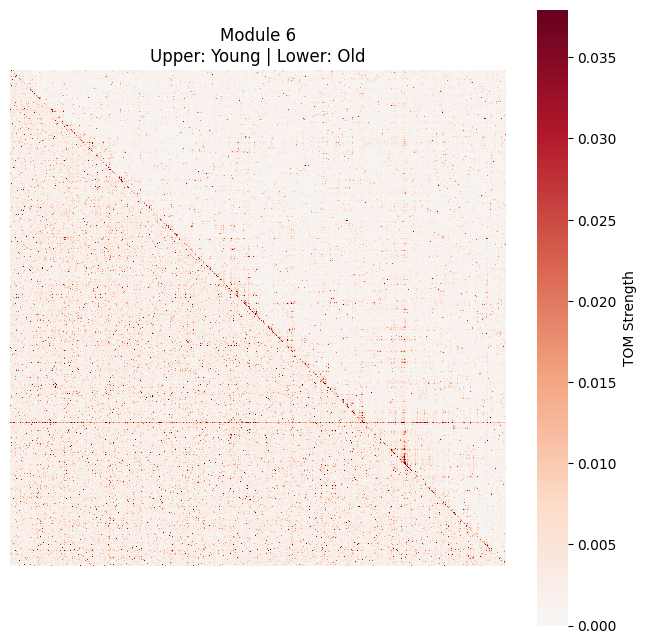

In [27]:
from scipy.cluster.hierarchy import ward, dendrogram, leaves_list
import seaborn as sns 
def plot_differential_module_heatmap(adj_young, adj_old, module_labels, target_module, 
                                     compute_tom=True, title_prefix="Module",
                                     vmax_percentile=99): # New parameter
    """
    Plots a composite heatmap.
    vmax_percentile: Saturates the heatmap at this percentile (e.g., 95) to show weak signals.
    """
    if isinstance(module_labels, dict):
        module_labels = pd.Series(module_labels)
        
    candidate_genes = module_labels[module_labels == target_module].index.tolist()
    valid_genes = [g for g in candidate_genes if g in adj_young.index and g in adj_old.index]
    
    if len(valid_genes) < 5: return
        
    sub_Y = adj_young.loc[valid_genes, valid_genes].values
    sub_O = adj_old.loc[valid_genes, valid_genes].values
    
    if compute_tom:
        def calc_simple_tom(adj):
            adj = np.clip(adj, 0, 1)
            np.fill_diagonal(adj, 0)
            L = np.dot(adj, adj)
            k = adj.sum(axis=1)
            k_min = np.minimum(k[:, None], k[None, :])
            denom = k_min + 1 - adj
            tom = (L + adj) / (denom + 1e-12)
            np.fill_diagonal(tom, 1)
            return tom

        matrix_Y = calc_simple_tom(sub_Y)
        matrix_O = calc_simple_tom(sub_O)
        label_type = "TOM"
    else:
        matrix_Y = sub_Y
        matrix_O = sub_O
        label_type = "Adjacency"

    # --- CONTRAST ENHANCEMENT ---
    # Calculate robust vmax from the data itself (ignoring diagonal 1s)
    all_vals = np.concatenate([matrix_Y[np.triu_indices_from(matrix_Y, k=1)], 
                               matrix_O[np.triu_indices_from(matrix_O, k=1)]])
    
    # Cap the scale at the 95th Percentile (or whatever you set)
    # This makes the "structure" pop out even if values are low.
    robust_vmax = np.percentile(all_vals, vmax_percentile)*2


    # Sorting
    dissim_Y = 1 - matrix_Y
    np.fill_diagonal(dissim_Y, 0)
    Z = linkage(squareform(dissim_Y, checks=False), method='average')
    sort_order = leaves_list(Z)
    
    composite = matrix_Y.copy()
    composite = composite[sort_order][:, sort_order]
    sorted_O = matrix_O[sort_order][:, sort_order]
    
    tril_indices = np.tril_indices_from(composite, k=-1)
    composite[tril_indices] = sorted_O[tril_indices] 
    np.fill_diagonal(composite, 0)
    
    plt.figure(figsize=(8, 8))
    # Note: vmax is now robust_vmax
    sns.heatmap(composite, cmap='RdBu_r', center=0, vmin=0, vmax=robust_vmax, square=True,
                xticklabels=False, yticklabels=False, cbar_kws={'label': f'{label_type} Strength'})
    
    plt.title(f"{title_prefix} {target_module}\nUpper: Young | Lower: Old")
    plt.show()
    
# Usage:
plot_differential_module_heatmap(young_brain_liver_multi_tissue, adj_old_aligned, module_map, target_module=6)

In [46]:
import gseapy as gp

def run_go_enrichment(module_labels, target_module, dataset='Reactome_Pathways_2024'):
    """
    Runs Enrichr API for a specific module gene list.
    """
    # 1. Get Genes (strip Tissue prefix if MultiIndex!)
    if isinstance(module_labels, dict):
        module_labels = pd.Series(module_labels)
        
    genes_with_tissue = module_labels[module_labels == target_module].index.tolist()
    
    # CRITICAL: Enrichr needs just gene symbols (e.g., 'INS'), not ('Liver', 'INS')
    # If your index is strings like "Liver_INS", you must split.
    # If MultiIndex, take level 1.
    
    clean_genes = []
    for g in genes_with_tissue:
        if isinstance(g, tuple): 
            clean_genes.append(g[1]) # Assuming (Tissue, Gene)
        elif "_" in g:
            # Dangerous assumption, but common: "Liver_Gene"
            clean_genes.append(g.split('_')[-1]) 
        else:
            clean_genes.append(g)
            
    clean_genes = list(set(clean_genes)) # Unique genes only
    print(f"Module {target_module}: Querying {len(clean_genes)} genes against {dataset}...")
    
    # 2. Run Enrichr
    try:
        enr = gp.enrichr(gene_list=clean_genes,
                         gene_sets=dataset,
                         organism='Human', # or 'Mouse'
                         outdir=None) # Don't write to disk
        
        # 3. Display Top Results
        results = enr.results
        # Filter for significant
        sig = results[results['Adjusted P-value'] < 0.05].sort_values('Adjusted P-value')
        
        if sig.empty:
            print("No significant terms found.")
            return clean_genes, results.head(5)
        else:
            print(f"Found {len(sig)} significant terms.")
            return clean_genes, sig[['Term', 'Adjusted P-value', 'Overlap', 'Genes']].head(10)
            
    except Exception as e:
        print(f"Enrichment failed: {e}")
        return clean_genes, pd.DataFrame()

# Usage:
clean_genes_mod2, go_results_mod2 = run_go_enrichment(module_map, 2)
clean_genes_mod6, go_results_mod6 = run_go_enrichment(module_map, 6)
clean_genes_mod7, go_results_mod7 = run_go_enrichment(module_map, 7)
clean_genes_mod5, go_results_mod5 = run_go_enrichment(module_map, 5)
clean_genes_mod8, go_results_mod8 = run_go_enrichment(module_map, 8)

Module 2: Querying 4570 genes against Reactome_Pathways_2024...
Found 5 significant terms.
Module 6: Querying 4157 genes against Reactome_Pathways_2024...
No significant terms found.
Module 7: Querying 110 genes against Reactome_Pathways_2024...
No significant terms found.
Module 5: Querying 210 genes against Reactome_Pathways_2024...
No significant terms found.
Module 8: Querying 412 genes against Reactome_Pathways_2024...
No significant terms found.


In [52]:
go_results_mod2

,Term,Adjusted P-value,Overlap,Genes
0,CD22 Mediated BCR Regulation,0.001811,34/70,IGHV2-5;IGHV1-2;IGHV3-23;IGHV4-34;IGHV4-59;IGH...
1,Classical Antibody-Mediated Complement Activation,0.016183,37/88,IGHV2-5;IGHV1-2;IGHV3-23;IGHV4-34;IGHV4-59;IGH...
2,Role of LAT2 NTAL LAB on Calcium Mobilization,0.016183,39/95,IGHV2-5;IGHV1-2;IGHV3-23;IGHV4-34;IGHV4-59;IGH...
3,Scavenging of Heme From Plasma,0.030955,37/92,IGHV2-5;IGHV1-2;IGHV3-23;IGHV4-34;IGHV4-59;IGH...
4,FCGR Activation,0.041486,37/94,IGHV2-5;IGHV1-2;IGHV3-23;IGHV4-34;IGHV4-59;IGH...


In [45]:
    clean_genes_mod5

['RHBG',
 'MORC2',
 'HNRNPA1P6',
 'HNRNPLP1',
 'RPL37P6',
 'LINC01002',
 'PCP2',
 'POU5F1P6',
 'BICD1',
 'RGS7',
 'ELSPBP1',
 'RNU4ATAC',
 'RPL5P28',
 'ESRRAP2',
 'GAL3ST3',
 'C5orf46',
 'SLC6A12',
 'RHOC',
 'ALPL',
 'ST13P10',
 'LINC01621',
 'RPL21P120',
 'PRDX2P3',
 'EIF4A1P5',
 'OR7E41P',
 'TACO1',
 'SF3B2',
 'IL20',
 'GPR156',
 'C11orf16',
 'RNU6-863P',
 'CSNK1G2P1',
 'GSDMA',
 'TLN2',
 'NCOA7-AS1',
 'SRRM1P3',
 'TMEM147',
 'LINC00967',
 'XBP1',
 'SNORA71C',
 'RABEPK',
 'LINC01721',
 'MGAT4EP',
 'TRBV6-2',
 'RPSAP49',
 'CCDC71L',
 'S100A12',
 'EIF1P3',
 'LINC00484',
 'SERPINB2',
 'RNU6-29P',
 'SPA17P1',
 'MED27',
 'ANXA2P1',
 'CLSTN2-AS1',
 'MCU',
 'RN7SL799P',
 'RN7SL748P',
 'GAPDHP32',
 'YDJC',
 'UBE2V1P1',
 'RPL5P13',
 'MT1HL1',
 'MT1X',
 'FAM20A',
 'PCDHGB6',
 'UBTFL10',
 'SLC15A4',
 'CLIP4',
 'LINC01993',
 'BANCR',
 'LINC01752',
 'TMEM92-AS1',
 'RNU6-890P',
 'CLEC18C',
 'PSMA2P3',
 'MPG',
 'KCNK4',
 'SAA3P',
 'LINC01070',
 'PPP1R13L',
 'MT-TD',
 'CISD3',
 'KRT18P11',
 'KRT17P1